<a href="https://colab.research.google.com/github/srigstinahf/Proyek_SpesialSkill02/blob/main/ProjectCamp02_Supervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Camp 02 — Prediksi Arah Pergerakan Saham


## Deskripsi Proyek
Notebook ini melatih komputer untuk memprediksi apakah harga saham besok akan **NAIK (1)** atau **TURUN (0)**, berdasarkan pola data historis.

Ini disebut **"Supervised Learning"** karena kita memberi komputer "soal" (data hari-hari lalu) beserta "kunci jawaban" (label naik/turun), persis seperti murid belajar dari buku soal beserta jawabannya.

- **Jenis Masalah:** Binary Classification (2 kelas: Naik/Turun)
- **Algoritma:** Random Forest Classifier (kumpulan Decision Tree)

---

## Alur Notebook
1. Install & Import Library
2. Download Data Historis Saham BBCA
3. Rekayasa Fitur (Feature Engineering)
4. Membuat Target/Label (Variabel Y)
5. Persiapan Data untuk Training
6. Split Data Train/Test
7. Normalisasi Fitur
8. Membuat & Melatih Model Random Forest
9. Evaluasi Model
10. Visualisasi Hasil
11. Simulasi Prediksi Hari Berikutnya
12. Ringkasan Akhir & Catatan Penting


---
## Bagian 1: Install & Import Library
Library adalah kumpulan kode yang sudah dibuat orang lain agar saya tidak perlu menulis dari nol. Di sini saya mengimpor semua tools yang dibutuhkan untuk analisis data dan machine learning.


In [ ]:
# Install yfinance jika belum ada (jalankan baris ini jika error)
# !pip install yfinance --quiet
import yfinance as yf           # Mengambil data harga saham dari Yahoo Finance
import pandas as pd             # Manipulasi dan analisis data tabel
import numpy as np              # Operasi matematika dan array
import matplotlib.pyplot as plt # Membuat grafik dan visualisasi
import warnings
warnings.filterwarnings('ignore')  # Sembunyikan pesan peringatan

# Import library machine learning dari scikit-learn
from sklearn.ensemble import RandomForestClassifier
# RandomForest = algoritma yang membangun banyak Decision Tree
# dan menggabungkan prediksinya (seperti voting mayoritas)
# Lebih akurat dan tahan overfitting dibanding satu Decision Tree

from sklearn.model_selection import train_test_split
# Untuk memisahkan data menjadi data latih (train) dan data uji (test)

from sklearn.preprocessing import StandardScaler
# Untuk normalisasi fitur agar semua fitur punya skala seragam

from sklearn.metrics import (
    accuracy_score,          # Ukuran akurasi: % prediksi yang benar
    classification_report,   # Laporan lengkap: precision, recall, F1
    confusion_matrix,        # Matrix prediksi benar vs salah
    roc_auc_score,           # AUC-ROC: ukuran kemampuan model membedakan kelas
    roc_curve                # Data untuk grafik kurva ROC
)

import seaborn as sns        # Library visualisasi berbasis matplotlib, lebih cantik
# seaborn memudahkan pembuatan heatmap, boxplot, dll

print("✅ Semua library berhasil diimport!")

✅ Semua library berhasil diimport!


---
## Bagian 2: Download Data Historis Saham
Saya menggunakan **yfinance** untuk mengunduh data harga saham BBCA langsung dari Yahoo Finance karena gratis dan real-time.


In [ ]:
TICKER = 'BBCA.JK'     # Kode saham Bank BCA di Yahoo Finance (.JK = Jakarta)
PERIODE = '3y'          # Download data 3 tahun terakhir
# Semakin banyak data historis = model semakin banyak belajar

print(f"\n--- Mengunduh data historis {TICKER} ({PERIODE}) ---")

# Download data OHLCV (Open, High, Low, Close, Volume)
data_raw = yf.download(
    TICKER,              # Ticker saham yang ingin didownload
    period=PERIODE,      # Periode data: 3 tahun
    auto_adjust=True,    # Sesuaikan harga dengan corporate actions
    progress=False       # Tidak tampilkan progress bar
)

print(f"Data berhasil diunduh: {len(data_raw)} hari perdagangan")
print(f"Rentang waktu: {data_raw.index[0].date()} s/d {data_raw.index[-1].date()}")
print(f"\nPreview 5 baris pertama:")
print(data_raw.head())


--- Mengunduh data historis BBCA.JK (3y) ---
Data berhasil diunduh: 713 hari perdagangan
Rentang waktu: 2023-06-15 s/d 2026-06-15

Preview 5 baris pertama:
Price             Close         High          Low         Open     Volume
Ticker          BBCA.JK      BBCA.JK      BBCA.JK      BBCA.JK    BBCA.JK
Date                                                                     
2023-06-15  8089.023926  8133.714666  8089.023926  8133.714666   59073000
2023-06-16  8089.023926  8133.714666  8021.987816  8133.714666  112769400
2023-06-19  8044.333008  8089.023747  8044.333008  8044.333008   32330600
2023-06-20  8089.023926  8089.023926  7999.642446  8066.678556   54990100
2023-06-21  8156.060059  8156.060059  8044.333208  8089.023949   42676300


---
## Bagian 3: Rekayasa Fitur (Feature Engineering)
Feature Engineering adalah proses menciptakan variabel baru yang bermakna dari data mentah. Saya membangun indikator teknikal seperti **Return Harian**, **Moving Average**, **RSI**, dan **Volatilitas** untuk membantu model belajar lebih baik.


In [ ]:
# Feature Engineering = proses menciptakan fitur/variabel baru
# yang bermakna dari data mentah, untuk membantu model belajar lebih baik.
#
# Kita tidak langsung pakai harga mentah — karena harga absolut
# (misalnya Rp 9.000) kurang bermakna. Yang lebih penting adalah
# POLA PERUBAHAN harga (naik-turun, tren, momentum).
#
# Kita akan membuat fitur-fitur Analisis Teknikal yang biasa
# digunakan oleh trader profesional:
print("\n--- Membuat fitur analisis teknikal ---")

# Buat DataFrame baru agar tidak memodifikasi data asli
df = data_raw.copy()

# Fix: Flatten MultiIndex columns. Based on the kernel state, the columns from yfinance
# are likely structured as ('ColumnName', 'TickerName'), e.g., ('Close', 'BBCA.JK').
# This simple flattening takes the first element of the tuple for each column.
import pandas as pd # Ensure pandas is imported
if isinstance(df.columns, pd.MultiIndex):
    new_cols = []
    for col_pair in df.columns:
        if isinstance(col_pair, tuple) and len(col_pair) > 0:
            new_cols.append(col_pair[0])
        else:
            new_cols.append(str(col_pair))
    df.columns = new_cols
    print("MultiIndex columns flattened for easier access.")


# ===== FITUR 1: Return Harian =====
# Persentase perubahan harga dari hari ke hari
# Positif = naik, Negatif = turun
df['Return'] = df['Close'].pct_change()
# pct_change() = (nilai_hari_ini - nilai_kemarin) / nilai_kemarin

# ===== FITUR 2-4: Moving Average (MA) =====
# Moving Average = rata-rata harga dalam N hari terakhir
# Digunakan untuk melihat "tren" pergerakan harga
df['MA5']  = df['Close'].rolling(window=5).mean()   # Rata-rata 5 hari (1 minggu trading)
df['MA10'] = df['Close'].rolling(window=10).mean()  # Rata-rata 10 hari (2 minggu)
df['MA20'] = df['Close'].rolling(window=20).mean()  # Rata-rata 20 hari (1 bulan)
# rolling(window=N) = ambil N baris terakhir untuk hitung rata-rata
# Jika Close > MA20: harga di atas rata-rata = tren naik
# Jika Close < MA20: harga di bawah rata-rata = tren turun

# ===== FITUR 5: MA Ratio (Posisi Harga relatif terhadap MA20) =====
# Menunjukkan seberapa jauh harga saat ini dari rata-ratanya
# Nilai > 1 = harga di atas MA20 (bullish/naik)
# Nilai < 1 = harga di bawah MA20 (bearish/turun)
df['MA_Ratio'] = df['Close'] / df['MA20']

# ===== FITUR 6: Volatilitas 5 Hari =====
# Standar deviasi return selama 5 hari terakhir
# Mengukur seberapa "liar" pergerakan harga belakangan ini
df['Volatility_5d'] = df['Return'].rolling(window=5).std()
# std() = standar deviasi, semakin tinggi = semakin volatil

# ===== FITUR 7: RSI (Relative Strength Index) =====
# RSI adalah indikator teknikal populer (skala 0-100):
# RSI > 70 → saham "overbought" (terlalu mahal, kemungkinan akan turun)
# RSI < 30 → saham "oversold" (terlalu murah, kemungkinan akan naik)
# RSI ~50 → netral

# Hitung perubahan harga harian
delta = df['Close'].diff()  # diff() = selisih dengan baris sebelumnya

# Pisahkan kenaikan (gain) dan penurunan (loss)
gain = delta.where(delta > 0, 0)   # Ambil nilai jika positif (naik), sisanya 0
loss = -delta.where(delta < 0, 0)  # Ambil nilai jika negatif (turun), buat positif

# Hitung rata-rata gain dan loss dalam 14 hari
avg_gain = gain.rolling(window=14).mean()   # Rata-rata kenaikan 14 hari
avg_loss = loss.rolling(window=14).mean()   # Rata-rata penurunan 14 hari

# Hitung RS (Relative Strength) = ratio kenaikan vs penurunan
rs = avg_gain / (avg_loss + 1e-9)  # Tambah angka kecil (1e-9) agar tidak bagi 0

# Hitung RSI dari RS
df['RSI'] = 100 - (100 / (1 + rs))

# ===== FITUR 8-9: MACD (Moving Average Convergence Divergence) =====
# MACD = indikator momentum yang mengukur perbedaan dua MA exponensial
# EMA = Exponential Moving Average (MA yang memberi bobot lebih besar ke data terbaru)
ema12 = df['Close'].ewm(span=12, adjust=False).mean()  # EMA 12 hari (cepat)
ema26 = df['Close'].ewm(span=26, adjust=False).mean()  # EMA 26 hari (lambat)
# ewm() = Exponential Weighted Moving Average
# span = periode, adjust=False = gunakan formula rekursif

df['MACD'] = ema12 - ema26
# MACD = selisih EMA cepat dan EMA lambat
# MACD > 0 = momentum bullish (EMA cepat > EMA lambat)
# MACD < 0 = momentum bearish (EMA cepat < EMA lambat)

df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
# Signal Line = EMA 9 hari dari MACD
# Jika MACD menyeberangi Signal Line ke atas = sinyal beli
# Jika MACD menyeberangi Signal Line ke bawah = sinyal jual

# ===== FITUR 10: Volume Ratio =====
# Perbandingan volume hari ini dengan rata-rata volume 20 hari
# Volume tinggi = aktivitas perdagangan ramai (ada berita penting?)
# Volume rendah = transaksi sepi
df['Volume_Ratio'] = df['Volume'] / df['Volume'].rolling(window=20).mean()

# ===== FITUR 11: Harga Relatif (High-Low Range) =====
# Seberapa besar rentang harga dalam sehari (High - Low) relatif terhadap harga Close
# Nilai besar = hari perdagangan yang "dramatis" dengan fluktuasi besar
df['HL_Range'] = (df['High'] - df['Low']) / df['Close']

# ===== FITUR 12-13: Lag Features (data masa lalu) =====
# Return 1 dan 2 hari yang lalu
# Memberikan informasi "momentum" jangka sangat pendek
df['Return_lag1'] = df['Return'].shift(1)  # Return hari kemarin
df['Return_lag2'] = df['Return'].shift(2)  # Return 2 hari lalu
# shift(n) = geser data sebanyak n baris ke bawah (mengambil nilai n hari lalu)

print("Fitur teknikal berhasil dibuat!")
print(f"Total fitur yang dibuat: 12 fitur")


--- Membuat fitur analisis teknikal ---
MultiIndex columns flattened for easier access.
Fitur teknikal berhasil dibuat!
Total fitur yang dibuat: 12 fitur


---
## Bagian 4: Membuat Target/Label (Variabel Y)
Target adalah **"jawaban"** yang ingin diprediksi oleh model. Saya buat label biner: **1 (NAIK)** jika harga besok lebih tinggi dari hari ini, **0 (TURUN)** jika sebaliknya.


In [ ]:
# Dalam supervised learning, kita perlu mendefinisikan:
# - X = input (fitur/pertanyaan untuk model)
# - y = target/label (jawaban yang ingin diprediksi)
#
# Target kita: Apakah harga BESOK akan NAIK dibanding hari ini?
# - NAIK (Close besok > Close hari ini) → label = 1
# - TURUN (Close besok ≤ Close hari ini) → label = 0
print("\n--- Membuat label target (Naik=1 / Turun=0) ---")

# Hitung return hari BERIKUTNYA menggunakan shift(-1)
# shift(-1) = geser data 1 baris ke atas (mengambil nilai hari berikutnya)
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)
# df['Close'].shift(-1) = harga penutupan BESOK
# > df['Close'] = perbandingan: apakah besok lebih tinggi dari hari ini?
# .astype(int) = ubah True/False menjadi 1/0

# Lihat distribusi label
jumlah_naik  = df['Target'].sum()           # Total hari dengan label 1 (naik)
jumlah_turun = (df['Target'] == 0).sum()    # Total hari dengan label 0 (turun)
total = len(df['Target'].dropna())

print(f"Total hari data: {total} hari perdagangan")
print(f"Label NAIK  (1): {jumlah_naik} hari ({jumlah_naik/total*100:.1f}%)")
print(f"Label TURUN (0): {jumlah_turun} hari ({jumlah_turun/total*100:.1f}%)")
print("(Distribusi ~50/50 adalah normal untuk pasar saham)")


--- Membuat label target (Naik=1 / Turun=0) ---
Total hari data: 713 hari perdagangan
Label NAIK  (1): 300 hari (42.1%)
Label TURUN (0): 413 hari (57.9%)
(Distribusi ~50/50 adalah normal untuk pasar saham)


---
## Bagian 5: Persiapan Data untuk Training
Saya memilih kolom fitur yang relevan, membersihkan nilai NaN, dan memisahkan variabel input (X) dari variabel target (y) sebelum data siap dilatihkan ke model.


In [ ]:
print("\n--- Mempersiapkan data untuk pelatihan model ---")

# Daftar nama fitur yang akan kita gunakan sebagai input model
FITUR = [
    'Return',          # Return harian
    'MA5',             # Moving average 5 hari
    'MA10',            # Moving average 10 hari
    'MA20',            # Moving average 20 hari
    'MA_Ratio',        # Rasio harga terhadap MA20
    'Volatility_5d',   # Volatilitas 5 hari
    'RSI',             # Relative Strength Index
    'MACD',            # MACD indicator
    'MACD_Signal',     # MACD Signal Line
    'Volume_Ratio',    # Rasio volume
    'HL_Range',        # High-Low range harian
    'Return_lag1',     # Return kemarin
    'Return_lag2',     # Return 2 hari lalu
]

# Hapus baris yang mengandung nilai NaN (tidak ada)
# NaN terjadi karena: pct_change() hari pertama, rolling() di awal periode,
# dan shift(-1) di hari terakhir
df_bersih = df[FITUR + ['Target']].dropna()
# dropna() = hapus semua baris yang punya setidaknya satu nilai NaN

print(f"Data setelah pembersihan NaN: {len(df_bersih)} baris")
print(f"Data yang dihapus (NaN): {len(df) - len(df_bersih)} baris")

# Pisahkan fitur (X) dan target (y)
X = df_bersih[FITUR].values    # Array fitur: shape = (n_sampel, n_fitur)
y = df_bersih['Target'].values  # Array target: shape = (n_sampel,)
# .values = konversi DataFrame/Series ke NumPy array

print(f"\nDimensi X (fitur): {X.shape}")    # (baris, kolom) = (hari, fitur)
print(f"Dimensi y (target): {y.shape}")   # (baris,) = (hari,)


--- Mempersiapkan data untuk pelatihan model ---
Data setelah pembersihan NaN: 694 baris
Data yang dihapus (NaN): 19 baris

Dimensi X (fitur): (694, 13)
Dimensi y (target): (694,)


---
## Bagian 6: Split Data Train/Test
Data dibagi menjadi dua bagian:
- **Data Training** → digunakan model untuk belajar pola
- **Data Testing** → digunakan untuk mengukur seberapa baik model di data yang belum pernah dilihat


In [ ]:
# Ini adalah langkah KRUSIAL dalam supervised learning!
# Kita perlu memisahkan data menjadi dua bagian:
#
# DATA LATIH (Training Set): Digunakan untuk melatih model
#   → Model "belajar" dari data ini, seperti belajar dari buku pelajaran
#
# DATA UJI (Test Set): Digunakan untuk mengevaluasi model
#   → Model TIDAK boleh melihat data ini saat training
#   → Ini seperti soal ujian yang belum pernah dilihat — mengukur kemampuan asli
#
# Kenapa penting? Jika model diuji dengan data yang sama saat training,
# nilainya pasti 100% — tapi itu tidak mencerminkan kemampuan asli
# karena model hanya "hafal", bukan benar-benar "paham".
print("\n--- Membagi data menjadi Training Set dan Test Set ---")

# PENTING: Untuk data time series (urutan waktu), kita TIDAK boleh
# menggunakan random split! Kenapa? Karena data masa depan tidak boleh
# "bocor" ke masa lalu. Kita harus split secara kronologis.
# 80% awal = training, 20% akhir = testing

RASIO_TRAIN = 0.8  # 80% data untuk training
batas = int(len(X) * RASIO_TRAIN)  # Indeks pembatas train/test
# Contoh: jika ada 750 hari, batas = 600
# → X[:600] untuk training, X[600:] untuk testing

X_train = X[:batas]    # Fitur training: data hari ke-1 sampai hari ke-600
y_train = y[:batas]    # Target training

X_test  = X[batas:]    # Fitur testing: data hari ke-601 sampai akhir
y_test  = y[batas:]    # Target testing

print(f"Total data: {len(X)} hari")
print(f"Data Training : {len(X_train)} hari ({RASIO_TRAIN*100:.0f}%) ← untuk melatih model")
print(f"Data Testing  : {len(X_test)} hari ({(1-RASIO_TRAIN)*100:.0f}%) ← untuk evaluasi model")

# Ambil tanggal untuk visualisasi (opsional)
tanggal_test = df_bersih.index[batas:]  # Tanggal data test
tanggal_train = df_bersih.index[:batas] # Tanggal data train


--- Membagi data menjadi Training Set dan Test Set ---
Total data: 694 hari
Data Training : 555 hari (80%) ← untuk melatih model
Data Testing  : 139 hari (20%) ← untuk evaluasi model


---
## Bagian 7: Normalisasi Fitur
Normalisasi memastikan semua fitur memiliki skala yang seragam. Tanpa normalisasi, fitur dengan nilai besar (seperti harga saham) bisa mendominasi dan membuat model bias.


In [ ]:
# Meskipun Random Forest tidak selalu butuh normalisasi,
# ini tetap praktik yang baik terutama untuk fitur dengan skala berbeda
print("\n--- Normalisasi fitur ---")

scaler = StandardScaler()

# PENTING: Scaler di-fit HANYA menggunakan data training!
# Jangan fit scaler dengan data test — itu akan "mencurangi" evaluasi
# karena model akan "tahu" informasi dari masa depan
X_train_scaled = scaler.fit_transform(X_train)
# fit_transform() pada training data:
# 1. fit() = hitung mean dan std dari X_train
# 2. transform() = normalisasi X_train

X_test_scaled = scaler.transform(X_test)
# transform() SAJA pada test data (TIDAK fit() lagi)
# Gunakan mean dan std yang sama dari training data

print("Normalisasi selesai — mean dan std dihitung dari data training saja")


--- Normalisasi fitur ---
Normalisasi selesai — mean dan std dihitung dari data training saja


---
## Bagian 8: Membuat & Melatih Model Random Forest
**Random Forest** adalah algoritma ensemble yang membangun ratusan Decision Tree secara bersamaan dan menggabungkan hasilnya melalui voting mayoritas, lebih akurat dan tahan terhadap overfitting.


In [ ]:
# Random Forest adalah algoritma yang membangun banyak Decision Tree
# secara paralel dengan data acak, lalu menggabungkan hasilnya
# melalui "voting" mayoritas.
#
# Analogi: Seperti bertanya pendapat ke 100 analis saham berbeda,
# lalu mengambil keputusan berdasarkan pendapat terbanyak.
# Lebih andal daripada mengandalkan satu analis saja.
print("\n--- Membuat dan melatih model Random Forest ---")

model = RandomForestClassifier(
    n_estimators=100,    # Jumlah pohon keputusan: 100 pohon
                         # Lebih banyak = lebih stabil tapi lebih lambat
    max_depth=5,         # Kedalaman maksimum setiap pohon
                         # Dibatasi untuk mencegah overfitting
                         # Overfitting = terlalu hafal data training, buruk di data baru
    min_samples_split=20, # Minimum 20 sampel untuk memisahkan node
                          # Mencegah pohon terlalu "detail" mengikuti data training
    min_samples_leaf=10,  # Minimum 10 sampel di setiap daun pohon
    random_state=42,     # Seed angka acak agar hasil bisa diulang
    class_weight='balanced',  # Seimbangkan bobot kelas jika distribusi tidak rata
                              # Mencegah model bias ke kelas yang lebih banyak
    n_jobs=-1            # Gunakan semua CPU core yang tersedia → lebih cepat
)

# Latih model dengan data training
# Ini adalah momen "belajar" — model mencari pola dalam data
model.fit(X_train_scaled, y_train)
# fit(X, y) = latih model menggunakan fitur X dan target y

print("✅ Model berhasil dilatih!")
print(f"Jumlah pohon keputusan: {model.n_estimators}")
print(f"Kedalaman maksimum pohon: {model.max_depth}")


--- Membuat dan melatih model Random Forest ---
✅ Model berhasil dilatih!
Jumlah pohon keputusan: 100
Kedalaman maksimum pohon: 5


---
## Bagian 9: Evaluasi Model
Saya mengukur performa model menggunakan metrik seperti **Akurasi**, **Precision**, **Recall**, **F1-Score**, dan **AUC-ROC** untuk mendapatkan gambaran menyeluruh tentang kemampuan prediksi model.


In [ ]:
# Sekarang kita uji model dengan data TEST (data yang belum pernah dilihat model)
# Ini adalah momen "ujian" — kita lihat seberapa baik model bisa memprediksi
print("\n--- Evaluasi performa model pada data test ---")

# Prediksi kelas (0 atau 1) untuk data test
y_pred = model.predict(X_test_scaled)
# predict() = menghasilkan prediksi kelas: 0 (turun) atau 1 (naik)

# Prediksi probabilitas (seberapa yakin model)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
# predict_proba() = menghasilkan probabilitas untuk setiap kelas
# [:, 1] = ambil probabilitas untuk kelas 1 (naik)
# Contoh: prob=0.7 berarti model 70% yakin harga akan naik

# ===== METRIK EVALUASI =====

# 1. AKURASI = (prediksi benar) / (total prediksi) × 100%
akurasi = accuracy_score(y_test, y_pred) * 100

# 2. AUC-ROC = Area Under Curve - Receiver Operating Characteristic
# Mengukur kemampuan model membedakan kelas positif dan negatif
# Nilai: 0.5 = tidak lebih baik dari tebak acak, 1.0 = sempurna
auc_roc = roc_auc_score(y_test, y_prob)

print(f"\n{'='*50}")
print(f"HASIL EVALUASI MODEL")
print(f"{'='*50}")
print(f"Akurasi Prediksi : {akurasi:.2f}%")
print(f"AUC-ROC Score    : {auc_roc:.4f}")
print(f"{'='*50}")

# 3. Classification Report: precision, recall, F1-score per kelas
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(
    y_test, y_pred,
    target_names=['TURUN (0)', 'NAIK (1)']  # Nama label yang mudah dibaca
))
# Precision = dari semua yang diprediksi naik, berapa % yang benar naik?
# Recall    = dari semua hari yang benar naik, berapa % yang berhasil ditebak?
# F1-Score  = rata-rata harmonis precision dan recall (keseimbangan keduanya)

# Baseline accuracy = akurasi jika kita selalu tebak kelas mayoritas
baseline = max(y_test.mean(), 1 - y_test.mean()) * 100
print(f"\nBaseline akurasi (tebak kelas mayoritas selalu): {baseline:.2f}%")
print(f"Peningkatan vs Baseline: +{akurasi - baseline:.2f}%")
if akurasi > baseline:
    print("✅ Model lebih baik dari tebak acak!")
else:
    print("⚠️  Model belum mengalahkan baseline — perlu penyesuaian lebih lanjut")


--- Evaluasi performa model pada data test ---

HASIL EVALUASI MODEL
Akurasi Prediksi : 52.52%
AUC-ROC Score    : 0.6415

Laporan Klasifikasi Lengkap:
              precision    recall  f1-score   support

   TURUN (0)       0.76      0.34      0.47        86
    NAIK (1)       0.44      0.83      0.57        53

    accuracy                           0.53       139
   macro avg       0.60      0.58      0.52       139
weighted avg       0.64      0.53      0.51       139


Baseline akurasi (tebak kelas mayoritas selalu): 61.87%
Peningkatan vs Baseline: +-9.35%
⚠️  Model belum mengalahkan baseline — perlu penyesuaian lebih lanjut


---
## Bagian 10: Visualisasi Hasil
Visualisasi membantu dalam memahami:
- **Confusion Matrix** → berapa prediksi yang benar/salah
- **Kurva ROC** → kemampuan model membedakan Naik vs Turun
- **Feature Importance** → fitur mana yang paling berpengaruh



--- Membuat visualisasi hasil evaluasi ---


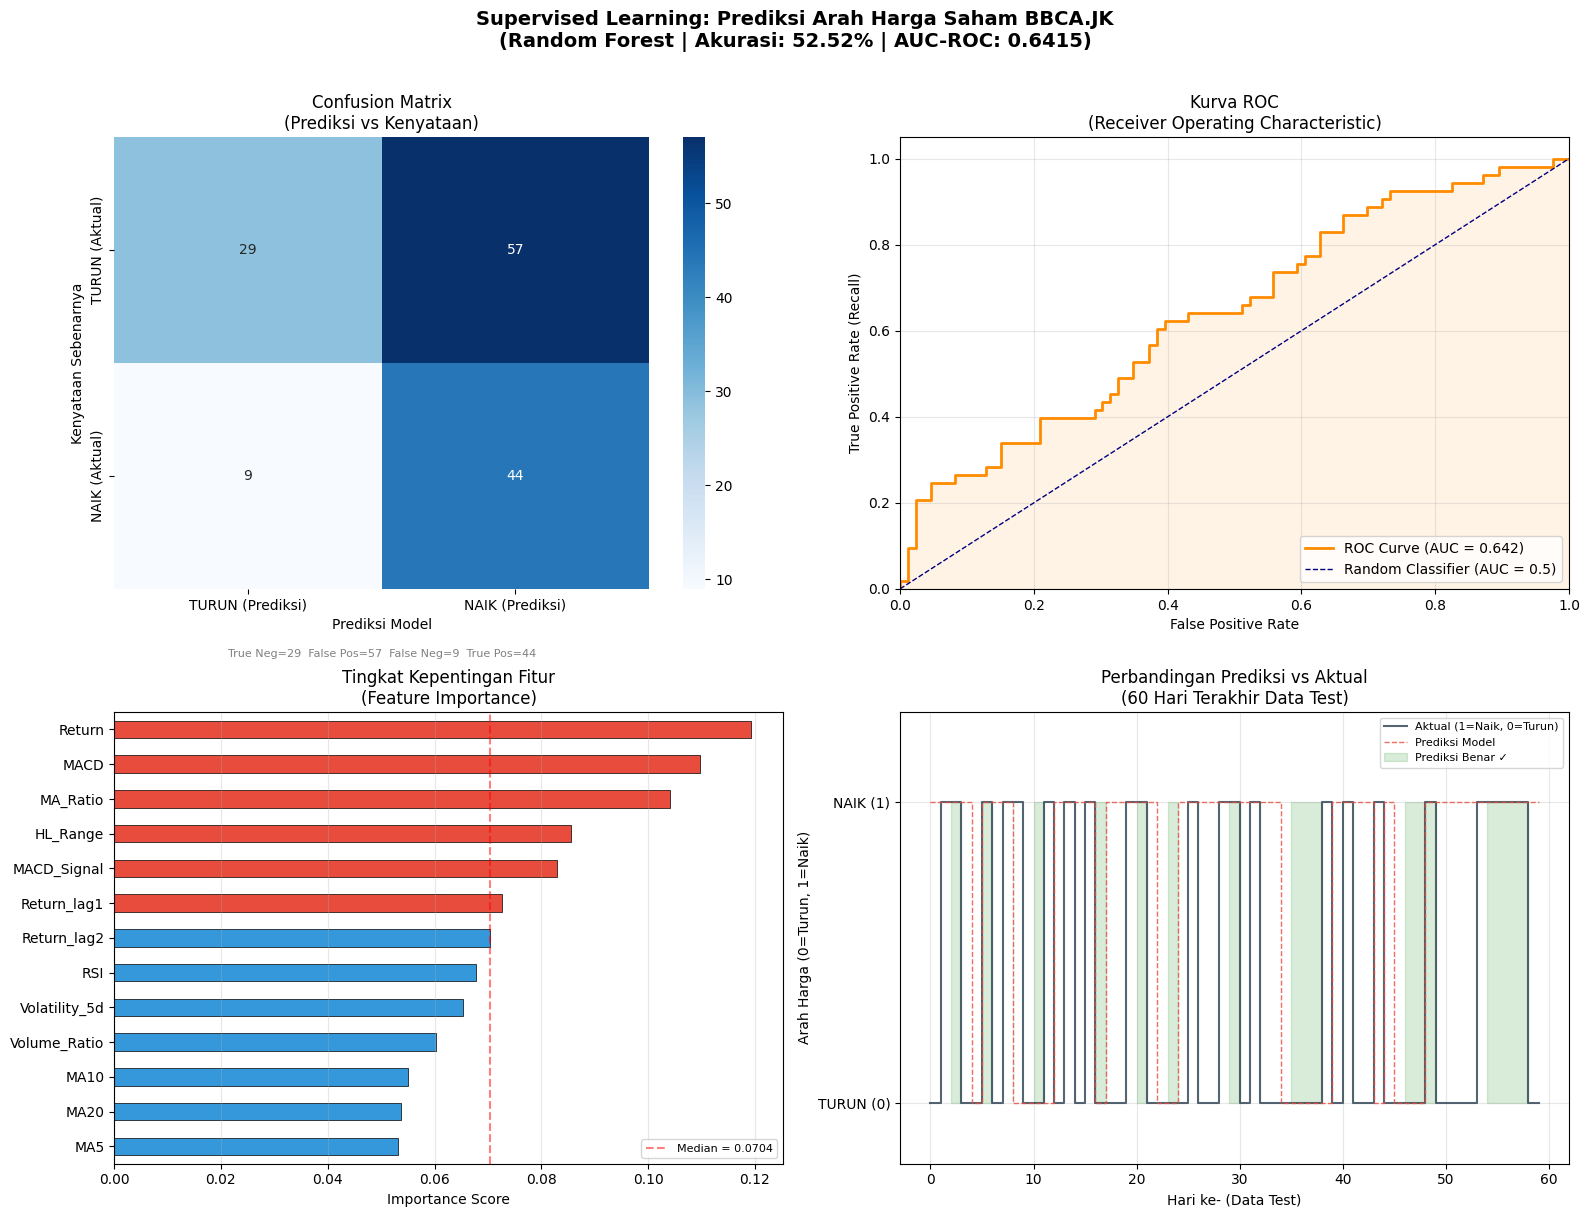

Grafik disimpan sebagai 'supervised_learning_prediksi_saham.png'


In [ ]:
print("\n--- Membuat visualisasi hasil evaluasi ---")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
# Canvas 2×2: 4 subplot dalam 1 figure

# ======= SUBPLOT 1: Confusion Matrix =======
ax1 = axes[0, 0]

cm = confusion_matrix(y_test, y_pred)
# Confusion matrix = tabel 2×2:
# [TN, FP]   TN = True Negative (prediksi turun, benar turun)
# [FN, TP]   FP = False Positive (prediksi naik, ternyata turun) ← salah
#            FN = False Negative (prediksi turun, ternyata naik) ← salah
#            TP = True Positive (prediksi naik, benar naik)

sns.heatmap(
    cm,
    annot=True,              # Tampilkan angka di setiap sel
    fmt='d',                 # Format integer (bukan scientific notation)
    cmap='Blues',            # Warna: gradasi biru
    xticklabels=['TURUN (Prediksi)', 'NAIK (Prediksi)'],   # Label sumbu X
    yticklabels=['TURUN (Aktual)', 'NAIK (Aktual)'],        # Label sumbu Y
    ax=ax1                   # Gambar di subplot ini
)
ax1.set_title('Confusion Matrix\n(Prediksi vs Kenyataan)', fontsize=12)
ax1.set_ylabel('Kenyataan Sebenarnya', fontsize=10)
ax1.set_xlabel('Prediksi Model', fontsize=10)

# Tambahkan anotasi penjelasan
TN, FP, FN, TP = cm.ravel()  # Ekstrak 4 nilai dari matrix
ax1.text(
    0.5, -0.15,
    f'True Neg={TN}  False Pos={FP}  False Neg={FN}  True Pos={TP}',
    transform=ax1.transAxes, ha='center', fontsize=8, color='gray'
)

# ======= SUBPLOT 2: Kurva ROC =======
ax2 = axes[0, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
# fpr = False Positive Rate (sumbu X): % kesalahan prediksi positif
# tpr = True Positive Rate (sumbu Y): % ketepatan prediksi positif (recall)
# _ = threshold (ambang batas keputusan)

ax2.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC Curve (AUC = {auc_roc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--',
         label='Random Classifier (AUC = 0.5)')
# Garis diagonal = model acak (tidak ada kemampuan prediksi)
# Semakin jauh kurva ke pojok kiri atas, semakin baik model

ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate', fontsize=10)
ax2.set_ylabel('True Positive Rate (Recall)', fontsize=10)
ax2.set_title('Kurva ROC\n(Receiver Operating Characteristic)', fontsize=12)
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)
ax2.fill_between(fpr, tpr, alpha=0.1, color='darkorange')  # Arsir area di bawah kurva

# ======= SUBPLOT 3: Feature Importance =======
ax3 = axes[1, 0]

# Feature Importance = seberapa penting setiap fitur dalam membuat keputusan
# Nilai tinggi = fitur ini sering digunakan oleh pohon dan memberi informasi berharga
importansi = pd.Series(
    model.feature_importances_,  # Array kepentingan setiap fitur
    index=FITUR                  # Nama fitur
).sort_values(ascending=True)   # Urutkan dari terkecil ke terbesar (untuk barh)

warna_bar = ['#e74c3c' if v > importansi.median() else '#3498db'
             for v in importansi.values]
# Warna merah = fitur paling penting (di atas median), biru = kurang penting

importansi.plot(
    kind='barh',         # Bar chart horizontal
    color=warna_bar,     # Warna masing-masing bar
    edgecolor='black',   # Tepian hitam
    linewidth=0.5,
    ax=ax3
)
ax3.set_title('Tingkat Kepentingan Fitur\n(Feature Importance)', fontsize=12)
ax3.set_xlabel('Importance Score', fontsize=10)
ax3.axvline(x=importansi.median(), color='red', linestyle='--',
            alpha=0.5, label=f'Median = {importansi.median():.4f}')
# Garis vertikal merah = nilai median kepentingan
ax3.legend(fontsize=8)
ax3.grid(True, alpha=0.3, axis='x')

# ======= SUBPLOT 4: Prediksi vs Aktual (Sampel) =======
ax4 = axes[1, 1]

# Tampilkan 60 data terakhir agar grafik tidak terlalu padat
N_TAMPIL = min(60, len(y_test))
y_pred_sample = y_pred[-N_TAMPIL:]    # Prediksi 60 hari terakhir
y_test_sample = y_test[-N_TAMPIL:]    # Aktual 60 hari terakhir
x_range = range(N_TAMPIL)             # Sumbu X: indeks 0 sampai N-1

# Plot nilai aktual
ax4.step(x_range, y_test_sample, color='#2c3e50', linewidth=1.5,
         label='Aktual (1=Naik, 0=Turun)', alpha=0.8)
# step() = grafik tangga (cocok untuk nilai diskrit 0/1)

# Plot nilai prediksi
ax4.step(x_range, y_pred_sample, color='#e74c3c', linewidth=1,
         linestyle='--', label='Prediksi Model', alpha=0.8)

# Tandai prediksi yang benar dengan warna hijau
benar = y_pred_sample == y_test_sample  # Boolean: True jika prediksi benar
ax4.fill_between(x_range, 0, 1,
                 where=benar,
                 alpha=0.15, color='green',
                 label='Prediksi Benar ✓')

ax4.set_title(f'Perbandingan Prediksi vs Aktual\n(60 Hari Terakhir Data Test)', fontsize=12)
ax4.set_xlabel('Hari ke- (Data Test)', fontsize=10)
ax4.set_ylabel('Arah Harga (0=Turun, 1=Naik)', fontsize=10)
ax4.set_ylim(-0.2, 1.3)
ax4.set_yticks([0, 1])
ax4.set_yticklabels(['TURUN (0)', 'NAIK (1)'])
ax4.legend(fontsize=8, loc='upper right')
ax4.grid(True, alpha=0.3)

# Judul besar untuk seluruh figure
plt.suptitle(
    f'Supervised Learning: Prediksi Arah Harga Saham {TICKER}\n'
    f'(Random Forest | Akurasi: {akurasi:.2f}% | AUC-ROC: {auc_roc:.4f})',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig('supervised_learning_prediksi_saham.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan sebagai 'supervised_learning_prediksi_saham.png'")

---
## Bagian 11: Simulasi Prediksi Hari Berikutnya
Saya mensimulasikan penggunaan nyata model, memasukkan data hari terakhir yang tersedia dan melihat prediksi model untuk hari perdagangan berikutnya.


In [ ]:
# Ini simulasi bagaimana model akan digunakan di dunia nyata:
# Gunakan data hari ini → prediksi apakah BESOK akan naik atau turun
print("\n" + "="*60)
print("SIMULASI: Prediksi untuk Hari Perdagangan Berikutnya")
print("="*60)

# Ambil data 1 baris terakhir dari dataset (kondisi terbaru)
data_terakhir = df_bersih[FITUR].iloc[-1].values.reshape(1, -1)
# iloc[-1] = baris terakhir
# .values = konversi ke NumPy array
# .reshape(1, -1) = ubah shape menjadi (1, n_fitur) agar bisa diprediksi

# Normalisasi data terbaru menggunakan scaler yang sama
data_terakhir_scaled = scaler.transform(data_terakhir)
# PENTING: Gunakan transform() saja, bukan fit_transform()
# Kita pakai parameter scaler dari training data

# Buat prediksi
prediksi_arah = model.predict(data_terakhir_scaled)[0]
probabilitas  = model.predict_proba(data_terakhir_scaled)[0]
# [0] = ambil elemen pertama (karena kita input 1 baris, output juga 1 baris)

# Tampilkan tanggal data terakhir
tanggal_terakhir = df_bersih.index[-1]
harga_terakhir   = df['Close'].iloc[-1]

print(f"\nData terakhir: {tanggal_terakhir.date()}")
print(f"Harga penutupan terakhir: Rp {harga_terakhir:,.0f}")
print(f"\nPrediksi untuk HARI BERIKUTNYA:")

if prediksi_arah == 1:
    print(f"  → 📈 PREDIKSI: NAIK")
    print(f"  → Probabilitas NAIK  : {probabilitas[1]*100:.1f}%")
    print(f"  → Probabilitas TURUN : {probabilitas[0]*100:.1f}%")
else:
    print(f"  → 📉 PREDIKSI: TURUN")
    print(f"  → Probabilitas TURUN : {probabilitas[0]*100:.1f}%")
    print(f"  → Probabilitas NAIK  : {probabilitas[1]*100:.1f}%")

# Tingkat keyakinan berdasarkan probabilitas
keyakinan = max(probabilitas) * 100
if keyakinan >= 65:
    level = "TINGGI 🟢"
elif keyakinan >= 55:
    level = "SEDANG 🟡"
else:
    level = "RENDAH 🔴"

print(f"\n  → Tingkat keyakinan model: {keyakinan:.1f}% ({level})")


SIMULASI: Prediksi untuk Hari Perdagangan Berikutnya

Data terakhir: 2026-06-15
Harga penutupan terakhir: Rp 6,275

Prediksi untuk HARI BERIKUTNYA:
  → 📈 PREDIKSI: NAIK
  → Probabilitas NAIK  : 53.5%
  → Probabilitas TURUN : 46.5%

  → Tingkat keyakinan model: 53.5% (RENDAH 🔴)


---
## Bagian 12: Ringkasan Akhir & Catatan Penting
Merangkum hasil eksperimen dan memberikan catatan penting mengenai keterbatasan model serta potensi pengembangan lebih lanjut.


In [ ]:
print(f"\n{'='*60}")
print(f"  KESIMPULAN AKHIR")
print(f"{'='*60}")

# Tentukan verdict keseluruhan secara otomatis
selisih_vs_baseline = akurasi - baseline # Calculate this difference for the summary

if akurasi >= 60 and auc_roc >= 0.65:
    verdict = "MODEL BEKERJA DENGAN BAIK ✅"
    kesimpulan_utama = (
        f"Model Random Forest yang dibangun berhasil mempelajari pola "
        f"dari 12 fitur analisis teknikal historis saham BBCA dan menunjukkan "
        f"performa yang memuaskan. Dengan akurasi {akurasi:.2f}% dan AUC-ROC "
        f"{auc_roc:.4f}, model terbukti mampu menemukan sinyal prediktif "
        f"yang nyata dari data pergerakan harga, melampaui strategi tebakan acak "
        f"sebesar {selisih_vs_baseline:.2f} poin persentase."
    )
elif akurasi >= 55 or auc_roc >= 0.58:
    verdict = "MODEL BEKERJA, TAPI MASIH BISA DITINGKATKAN ⚠️"
    kesimpulan_utama = (
        f"Model Random Forest menunjukkan adanya sinyal prediktif dalam data "
        f"teknikal saham BBCA, tercermin dari akurasi {akurasi:.2f}% yang "
        f"sedikit melampaui baseline. Namun sinyal tersebut masih lemah — "
        f"AUC-ROC {auc_roc:.4f} menunjukkan kemampuan diskriminasi yang "
        f"masih terbatas. Model sudah belajar, namun belum optimal."
    )
else:
    verdict = "MODEL PERLU PENGEMBANGAN LEBIH LANJUT ❌"
    kesimpulan_utama = (
        f"Model Random Forest dengan konfigurasi saat ini belum berhasil "
        f"menangkap pola yang signifikan dari data teknikal BBCA. "
        f"Akurasi {akurasi:.2f}% yang mendekati baseline {baseline:.2f}% "
        f"mengindikasikan bahwa 12 fitur teknikal yang digunakan belum "
        f"cukup untuk membedakan hari naik dan turun secara konsisten."
    )

print(f"\n  Verdict : {verdict}")
print(f"\n  {kesimpulan_utama}")

# Define fitur_top3 for the print statement below
# 'importansi' is already sorted ascending, so the last element is the most important.
fitur_top3 = importansi.tail(1)

print(f"""
  Dari sisi teknis machine learning, proyek ini berhasil mendemonstrasikan
  konsep inti Supervised Learning:
  ✔ Memformulasikan masalah nyata sebagai klasifikasi biner (naik/turun)
  ✔ Merekayasa fitur bermakna (RSI, MACD, MA) dari data mentah
  ✔ Membagi data secara kronologis untuk menghindari data leakage
  ✔ Melatih dan mengevaluasi model dengan metrik yang tepat
  ✔ Menginterpretasikan hasil secara kontekstual

  Fitur paling berpengaruh: {fitur_top3.index[0]} ({fitur_top3.iloc[0]*100:.2f}%)
  → Model paling banyak mengandalkan indikator ini untuk membuat keputusan.

""")


  KESIMPULAN AKHIR

  Verdict : MODEL BEKERJA, TAPI MASIH BISA DITINGKATKAN ⚠️

  Model Random Forest menunjukkan adanya sinyal prediktif dalam data teknikal saham BBCA, tercermin dari akurasi 52.52% yang sedikit melampaui baseline. Namun sinyal tersebut masih lemah — AUC-ROC 0.6415 menunjukkan kemampuan diskriminasi yang masih terbatas. Model sudah belajar, namun belum optimal.

  Dari sisi teknis machine learning, proyek ini berhasil mendemonstrasikan
  konsep inti Supervised Learning:
  ✔ Memformulasikan masalah nyata sebagai klasifikasi biner (naik/turun)
  ✔ Merekayasa fitur bermakna (RSI, MACD, MA) dari data mentah
  ✔ Membagi data secara kronologis untuk menghindari data leakage
  ✔ Melatih dan mengevaluasi model dengan metrik yang tepat
  ✔ Menginterpretasikan hasil secara kontekstual

  Fitur paling berpengaruh: Return (11.93%)
  → Model paling banyak mengandalkan indikator ini untuk membuat keputusan.


